In [1]:
import cv2
import sys

print(sys.executable)
print(cv2.__version__)
print(hasattr(cv2.dnn, 'readNetFromCaffe'))

C:\Users\acer\cv4env\Scripts\python.exe
4.11.0
True


In [2]:
import cv2

print(cv2.__version__)
print(hasattr(cv2.dnn, 'readNetFromCaffe'))

4.11.0
True


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [4]:
config_file = 'deploy.prototxt'
weights = 'mobilenet_iter_73000.caffemodel'

In [5]:
net = cv2.dnn.readNetFromCaffe(config_file, weights)
print("Model loaded successfully")

Model loaded successfully


In [6]:
class_labels = {
    0: 'background',
    1: 'aeroplane',
    2: 'bicycle',
    3: 'bird',
    4: 'boat',
    5: 'bottle',
    6: 'bus',
    7: 'car',
    8: 'cat',
    9: 'chair',
    10: 'cow',
    11: 'diningtable',
    12: 'dog',
    13: 'horse',
    14: 'motorbike',
    15: 'person',
    16: 'pottedplant',
    17: 'sheep',
    18: 'sofa',
    19: 'train',
    20: 'tvmonitor'
}

print("Class labels created successfully")

Class labels created successfully


In [7]:
image = cv2.imread('download.webp')

(h, w) = image.shape[:2]

print("Image loaded successfully")
print("Height:", h)
print("Width:", w)

Image loaded successfully
Height: 316
Width: 474


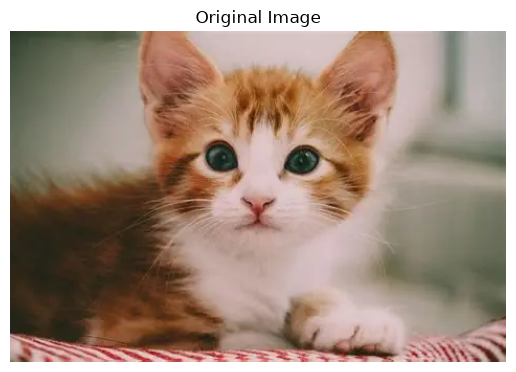

In [8]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [9]:
blob = cv2.dnn.blobFromImage(
    image,
    0.007843,
    (300, 300),
    127.5
)

print("Blob created successfully")

Blob created successfully


In [10]:
net.setInput(blob)

detections = net.forward()

print("Object detection completed successfully")

Object detection completed successfully


In [11]:
for i in range(detections.shape[2]):

    confidence = detections[0, 0, i, 2]

    if confidence > 0.5:

        index = int(detections[0, 0, i, 1])
        label = class_labels[index]

        box = detections[0, 0, i, 3:7] * np.array([w, h, w, h])

        (startX, startY, endX, endY) = box.astype("int")

        cv2.rectangle(image_rgb, (startX, startY), (endX, endY), (0, 255, 0), 2)

        cv2.putText(image_rgb, label, (startX, startY - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

print("Rectangles and labels added successfully")

Rectangles and labels added successfully


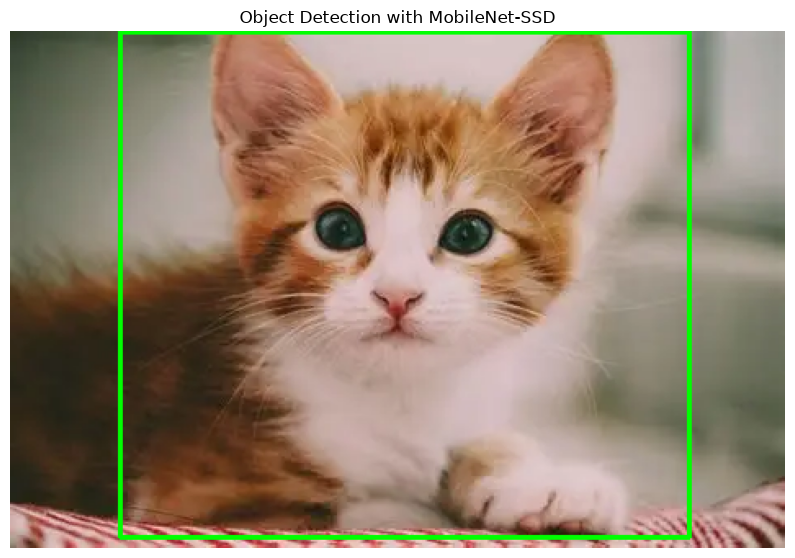

In [12]:
plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.title("Object Detection with MobileNet-SSD")
plt.axis("off")
plt.show()